In [9]:
!pip install numpy matplotlib

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\creat\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [18]:
import os, sys, io, time, math, pickle, contextlib, importlib
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

sys.path.insert(0, os.getcwd())
import graph, IndexMinPQ, search          # graph must be importable BEFORE unpickling
for m in (graph, IndexMinPQ, search):      # pick up edits to search.py without restarting
    importlib.reload(m)
from search import BFS, Dijkstra, aStar

DATASET = 'kennebec.pickle'    
START, TARGET = 31358, 101336  

with open(DATASET, 'rb') as f:
    G = pickle.load(f)
print(G, '| start label:', G.getTags(START).get('label'), '| target label:', G.getTags(TARGET).get('label'))

Graph(|V|=103959, |E|=215864) | start label: 101839649 | target label: 8494803044


In [19]:
verts = G.getVertices()
ids   = np.array([v.id for v in verts])
lat   = np.zeros(ids.max() + 1); lon = np.zeros(ids.max() + 1)
for v in verts:
    lat[v.id], lon[v.id] = v.tags['lat'], v.tags['lon']

seen, segs = set(), []
for v in verts:
    for e in G.edgesOf(v.id):
        key = (min(e.s, e.t), max(e.s, e.t))
        if key not in seen:
            seen.add(key)
            segs.append(((lon[e.s], lat[e.s]), (lon[e.t], lat[e.t])))
print(f'{len(verts):,} vertices, {len(segs):,} undirected edges')

103,959 vertices, 107,898 undirected edges


In [20]:
ALGOS = {'BFS': BFS, 'Dijkstra': Dijkstra, 'A*': aStar}

def path_weight(path):
    total = 0.0
    for a, b in zip(path, path[1:]):
        total += min(e.weight for e in G.edgesOf(a) if e.t == b)
    return total

def run_all(s, t):
    out = {}
    for name, fn in ALGOS.items():
        trace = []
        with contextlib.redirect_stdout(io.StringIO()):
            t0 = time.perf_counter()
            path, dist, pops = fn(G, s, t, trace=trace)
            secs = time.perf_counter() - t0
        out[name] = dict(path=path, edges=len(path) - 1, weight=path_weight(path) if path else float('nan'),
                         pops=pops, trace=trace, secs=secs)
    return out

results = run_all(START, TARGET)
print(f"{'algo':10s}{'pops':>10s}{'edges':>8s}{'weight':>12s}{'seconds':>10s}")
for n, r in results.items():
    print(f"{n:10s}{r['pops']:>10,d}{r['edges']:>8d}{r['weight']:>12.6f}{r['secs']:>10.3f}")
if len(results['A*']['path']) <= 25:
    lab = lambda p: [G.getTags(v).get('label', v) for v in p]
    for n, r in results.items():
        print(n, lab(r['path']))

algo            pops   edges      weight   seconds
BFS           16,099     136    0.084627     0.013
Dijkstra      23,416     223    0.078767     0.140
A*            10,328     223    0.078767     0.086


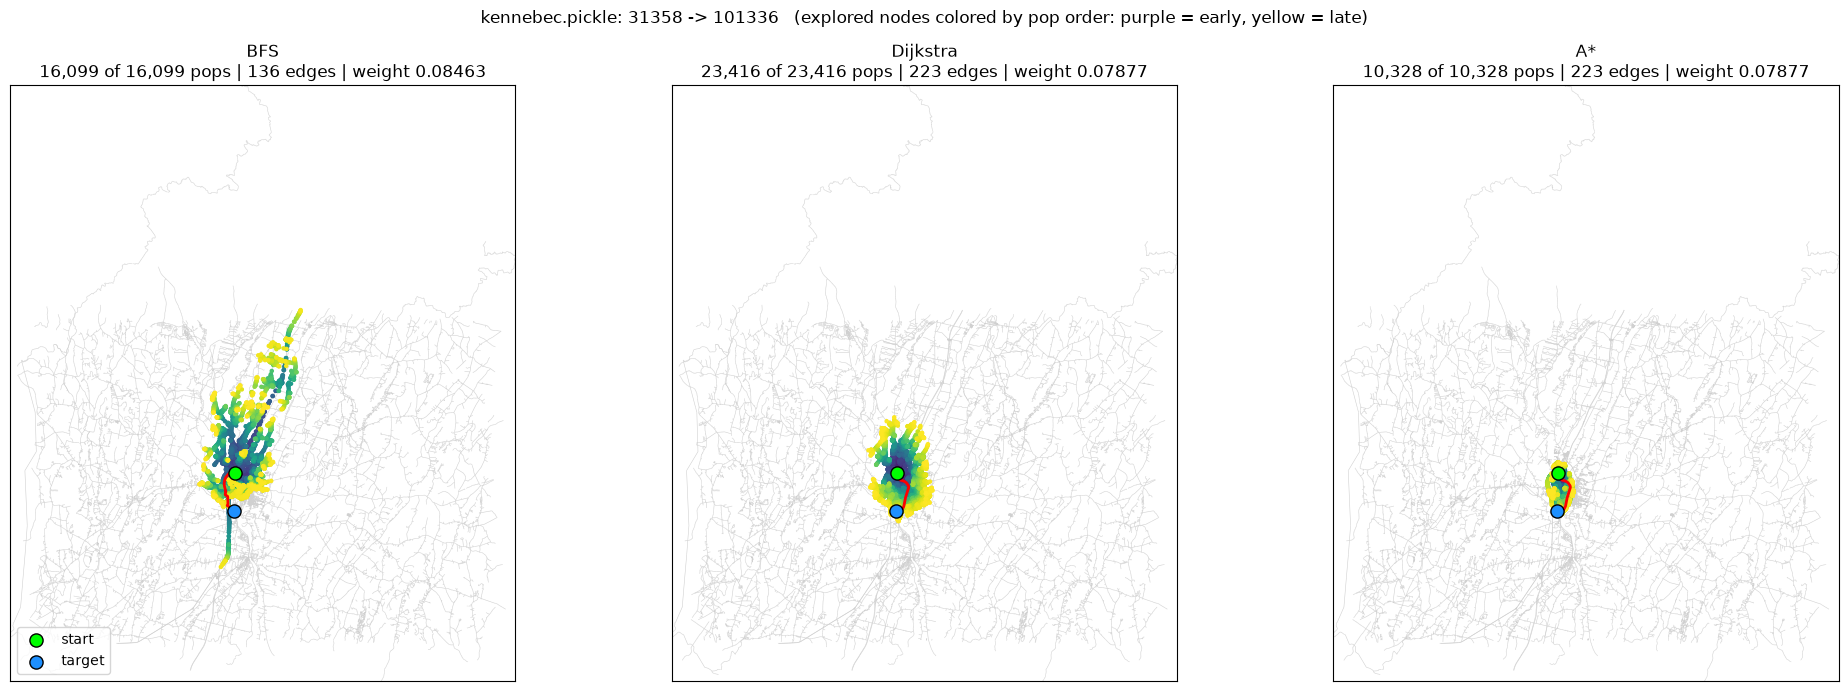

In [21]:
def draw_panel(ax, name, res, s, t, k=None):
    ax.add_collection(LineCollection(segs, colors='#d0d0d0', linewidths=0.4, zorder=1))
    trace = res['trace'] if k is None else res['trace'][:k]
    if trace:
        idx = np.asarray(trace)
        ax.scatter(lon[idx], lat[idx], c=np.arange(len(idx)), cmap='viridis', s=5, zorder=2)
    if res['path'] and (k is None or k >= len(res['trace'])):
        p = np.asarray(res['path'])
        ax.plot(lon[p], lat[p], color='red', lw=2, zorder=3)
    ax.scatter(lon[s], lat[s], c='lime', s=90, edgecolors='k', zorder=4, label='start')
    ax.scatter(lon[t], lat[t], c='dodgerblue', s=90, edgecolors='k', zorder=4, label='target')
    ax.set_xlim(lon[ids].min(), lon[ids].max()); ax.set_ylim(lat[ids].min(), lat[ids].max())
    ax.set_aspect(1 / math.cos(math.radians(lat[ids].mean())))   # undo lon stretching
    shown = len(trace)
    ax.set_title(f"{name}\n{shown:,} of {res['pops']:,} pops | {res['edges']} edges | weight {res['weight']:.5f}")
    ax.set_xticks([]); ax.set_yticks([])

fig, axes = plt.subplots(1, 3, figsize=(20, 7))
for ax, (name, res) in zip(axes, results.items()):
    draw_panel(ax, name, res, START, TARGET)
axes[0].legend(loc='lower left')
fig.suptitle(f'{DATASET}: {START} -> {TARGET}   (explored nodes colored by pop order: purple = early, yellow = late)')
plt.tight_layout(); plt.show()

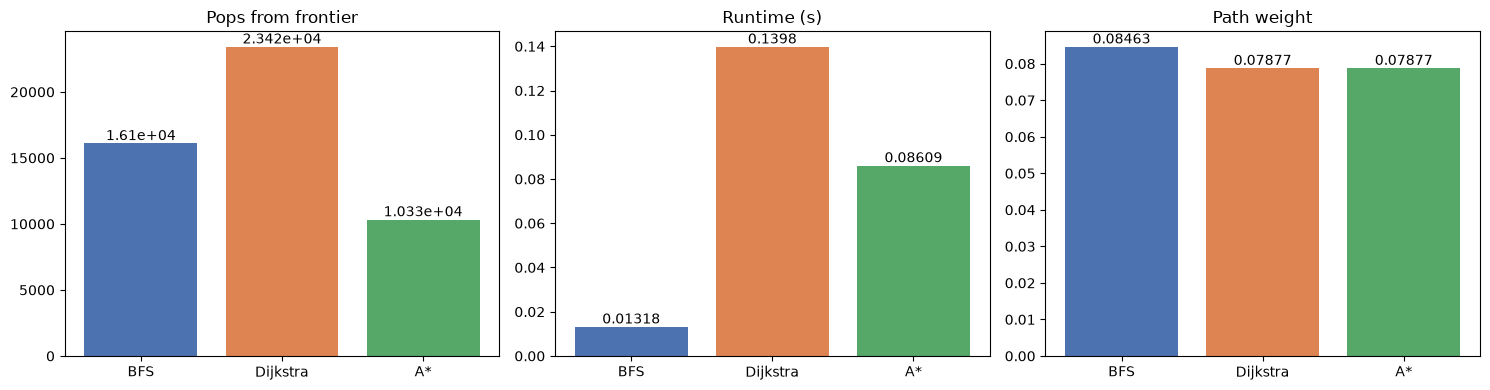

In [22]:
names = list(results)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, key, title in zip(axes, ['pops', 'secs', 'weight'], ['Pops from frontier', 'Runtime (s)', 'Path weight']):
    vals = [results[n][key] for n in names]
    bars = ax.bar(names, vals, color=['#4c72b0', '#dd8452', '#55a868'])
    ax.set_title(title); ax.bar_label(bars, fmt='%.4g')
plt.tight_layout(); plt.show()